# 06 · Example predictions

Train the selected XGBoost pipeline on batch 0 using the same grouped split as notebook 05. It excludes `status` and `prev_sold_date`. This is an exploratory model, not an MLflow champion.


## Imports

In [1]:
import json
import sys
import os
from pathlib import Path
import pandas as pd

sys.path.insert(0, str(Path('../src').resolve()))
from property_ml.features import RAW_FEATURES, build_model, prepare
from property_ml.splitting import assign_splits


## Load batch

In [2]:
DATA = Path('../data')
GROUP = int(os.environ['DATA_API_GROUP'])
files = sorted(DATA.glob(f'group-{GROUP}-*.json'))
if not files:
    raise FileNotFoundError('Collect a batch in notebook 01 first.')
with files[0].open() as file:
    batch = json.load(file)
df = pd.DataFrame(batch['data'])
print(f"Group {GROUP} | batch {batch['batch_number']} | {len(df):,} rows")


Group 4 | batch 0 | 73,784 rows


## Prepare and split

In [3]:
data = df.loc[df['price'].notna() & df['price'].gt(0)].copy()
raw_features = RAW_FEATURES
X, y = data[RAW_FEATURES].copy(), data['price']
splits = assign_splits(data)
X_train, X_test = X.loc[splits == 'train'], X.loc[splits == 'test']
X_validation = X.loc[splits == 'validation']
y_train, y_test = y.loc[splits == 'train'], y.loc[splits == 'test']
print('Training / held-out test:', len(X_train), len(X_test))


Training / held-out test: 44123 14647


## Train model

In [4]:
model = build_model()
model.fit(X_train, y_train)
print('Selected XGBoost pipeline ready.')


Selected XGBoost pipeline ready.


## Predict held-out properties

In [5]:
examples = X_test.sample(n=min(5, len(X_test)), random_state=42)
comparison = examples[raw_features].copy()
comparison['actual_price'] = y_test.loc[examples.index]
comparison['predicted_price'] = model.predict(examples)
comparison['absolute_error'] = (comparison['actual_price'] - comparison['predicted_price']).abs()
display(comparison.round(2))


,bed,bath,acre_lot,house_size,brokered_by,street,city,state,zip_code,actual_price,predicted_price,absolute_error
70659,3.0,2.0,0.12,1839.0,4825.0,575398.0,Odessa,Texas,79762.0,284900.0,244826.312500,40073.67
46275,3.0,2.0,0.30,2800.0,35421.0,1731603.0,Faribault,Minnesota,55021.0,264900.0,225302.921875,39597.08
18907,2.0,2.0,0.31,13583.0,48799.0,1680879.0,Atlanta,Georgia,30308.0,6000.0,216156.875000,210156.88
54186,4.0,4.0,0.20,2662.0,84621.0,1711180.0,Raytown,Missouri,64138.0,224900.0,247264.859375,22364.86
43995,5.0,2.0,0.07,2064.0,105309.0,641206.0,Milwaukee,Wisconsin,53204.0,99900.0,192416.062500,92516.06


## Try one property

Edit the input values; `price` is not an input.

In [6]:
example = data.loc[X_test.index[:1], raw_features].copy()
# Example: example.loc[:, 'bed'] = 3
print('Inputs:')
display(example)
predicted_price = model.predict(example)[0]
print(f'Predicted dataset price: {predicted_price:,.2f}')


Inputs:


,bed,bath,acre_lot,house_size,brokered_by,street,city,state,zip_code
1,3.0,2.0,0.87,1850.0,107951.0,1336295.0,Vernon,Connecticut,6066.0


Predicted dataset price: 249,926.38


The target can be a listing or recent sale price. These sample predictions are for exploration; they are not a trained MLflow champion or a guarantee of a sale price.

## Feature contributions on validation data

numeric__bath                                  12172.175781
numeric__acre_lot                               5700.267090
categorical__state_Ohio                         3186.639404
categorical__state_Texas                        2840.361084
categorical__state_New York                     2760.020996
categorical__state_Florida                      2687.198486
numeric__house_size                             2393.891113
numeric__bed                                    2021.758057
categorical__state_Illinois                     1492.040283
numeric__size_per_room                          1293.627075
categorical__brokered_by_infrequent_sklearn     1147.936890
categorical__state_Minnesota                    1026.501709
Name: Mean absolute SHAP value, dtype: float32

<Axes: title={'center': 'Feature contributions on validation data'}>

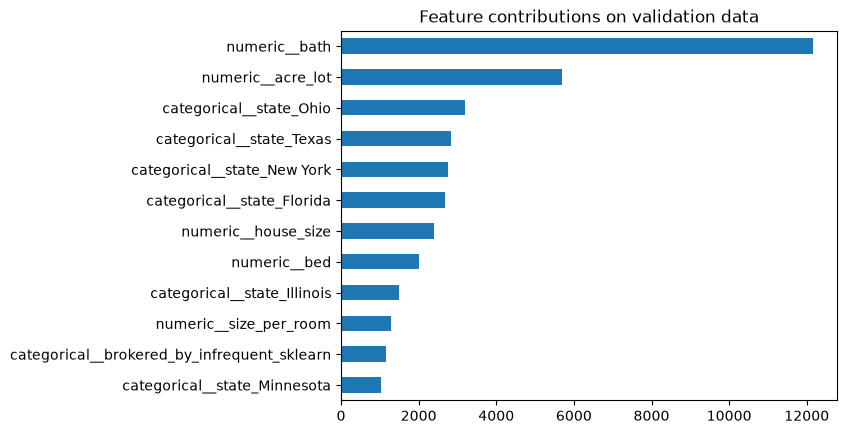

In [7]:
from property_ml.explain import shap_importance

importance = shap_importance(model, X_validation)
display(importance.head(12).rename('Mean absolute SHAP value'))
importance.head(12).sort_values().plot.barh(title='Feature contributions on validation data')
